# D4 Validation: HSE Resume-Job Matching Dataset

Source: https://www.kaggle.com/datasets/darysha/hse-hackathon

This notebook answers every question the instructor asked about D4. The column names below come
from the dataset's own data card, so the code uses the real names instead of guessing.

| # | Instructor's question | Section |
|---|---|---|
| 1 | Examine the actual structure (resumes, vacancies, IDs, labels) | 2 |
| 2 | Does it support ranking multiple jobs for each applicant? | 4 |
| 3 | Distribution of positive and negative labels | 3 |
| 4 | Job categories | 6 |
| 5 | Missing values and duplicate records | 7 |
| 6 | Limitations of recruitment outcomes as relevance labels | 10 |

**Three findings from the data card that the cells below confirm on the real file.
Read these before running, because they change how the project has to be built.**

1. **The label values are Russian, not English.** The card describes them as Invitation and Rejection,
   but the stored values are `Приглашение` (invitation, 14%) and `Отказ` (rejection, 86%).
2. **The explicit skill fields are almost always empty.** `skills_cv` is `[]` in 93% of rows and
   `skills_vacancy` is `[]` in 93%. Skills have to be extracted from free text instead.
3. **This is a general labour market dataset, not an AI or tech one.** The largest professional
   spheres are manufacturing (12%) and healthcare (10%), and the most common job title is accountant.

**The file is pipe-separated.** Every `read_csv` call below passes `sep="|"`. The free-text fields are
written in Russian and contain many commas, so a comma separator would break the file into the wrong
columns. This is worth mentioning in the data preprocessing section of the report.

**Before running,** put the HSE file in `datasets/`. The notebook finds it by itself.

## 1. Setup

In [1]:
import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4)
pd.set_option("display.max_columns", 100)

# Work from the project folder, even when Jupyter opens inside notebooks/
if Path.cwd().name == "notebooks":
    os.chdir("..")

CSV_PATH = "datasets/HSE_dataset(D4).csv"
if not Path(CSV_PATH).exists():
    found = [p for p in Path("datasets").glob("*.csv") if "hse" in p.name.lower()]
    if not found:
        raise FileNotFoundError("Put the HSE csv file in the datasets/ folder")
    CSV_PATH = str(found[0])

SEP = "|"        # this file is separated by |, not by commas
os.makedirs("figures", exist_ok=True)

print(CSV_PATH)
print(f"{os.path.getsize(CSV_PATH)/1e6:.1f} MB")

datasets/HSE_dataset(D4).csv
1020.3 MB


### 1.1 Column names we rely on

These are confirmed from the data card. The file has about 91 columns, so we read only what we need.

In [2]:
ID_CV        = "idCv"            # resume id
ID_VACANCY   = "idVacancy"       # vacancy id
LABEL        = "cv_status"       # Приглашение / Отказ
POSITIVE     = "Приглашение"     # invitation

# Candidate side
CV_POSITION  = "positionName"        # desired job position
CV_SKILLS    = "skills_cv"
CV_HARD      = "hardSkills_cv"
CV_SOFT      = "softSkills_cv"
CV_WORK      = "workExperienceList" # JSON list with company, dates, demands text
CV_EDU       = "educationList"
CV_EXP       = "experience"          # years
CV_REGION    = "localityName"
CV_DATE      = "dateCreate"

# Vacancy side
VC_NAME      = "vacancyName"
VC_SPHERE    = "professionalSphereName"   # 35 categories
VC_REQ       = "positionRequirements"
VC_RESP      = "responsibilities"
VC_QUAL      = "qualifications"
VC_SKILLS    = "skills_vacancy"
VC_HARD      = "hardSkills_vacancy"
VC_SOFT      = "softSkills_vacancy"
VC_EXP       = "experienceRequirements"
VC_REGION    = "regionName"
VC_DATE      = "datePublished"

USE_COLS = [ID_CV, ID_VACANCY, LABEL,
            CV_POSITION, CV_SKILLS, CV_HARD, CV_SOFT, CV_WORK, CV_EDU, CV_EXP, CV_REGION, CV_DATE,
            VC_NAME, VC_SPHERE, VC_REQ, VC_RESP, VC_QUAL, VC_SKILLS, VC_HARD, VC_SOFT, VC_EXP,
            VC_REGION, VC_DATE]

## 2. Load and check the structure

In [3]:
path = CSV_PATH

# Check the real header first, in case a name differs
header = pd.read_csv(path, sep=SEP, nrows=0).columns.tolist()
print("Total columns in file:", len(header))

missing_names = [c for c in USE_COLS if c not in header]
if missing_names:
    print("\nThese names were not found, fix them before continuing:")
    for c in missing_names:
        print("  -", c)
else:
    print("All expected columns are present.")

Total columns in file: 91
All expected columns are present.


In [4]:
cols = [c for c in USE_COLS if c in header]
df = pd.read_csv(path, sep=SEP, usecols=cols)

print("Rows (applications):", f"{len(df):,}")
print("Unique resumes     :", f"{df[ID_CV].nunique():,}")
print("Unique vacancies   :", f"{df[ID_VACANCY].nunique():,}")
df.head(3)

Rows (applications): 150,493
Unique resumes     : 65,714
Unique vacancies   : 43,756


,idCv,idVacancy,cv_status,localityName,positionName,dateCreate,skills_cv,experience,educationList,hardSkills_cv,softSkills_cv,workExperienceList,vacancyName,professionalSphereName,hardSkills_vacancy,softSkills_vacancy,skills_vacancy,experienceRequirements,datePublished,regionName,positionRequirements,qualifications,responsibilities
0,a4419ef0-93f4-11ec-a2fe-839f0d9a4379,72606f42-0c46-11ed-88f6-bf2cfe8c828d,Отказ,"Томская-область,-Колпашевский-район,-г-Колпашево",Музыкальный-руководитель,2022-02-22T18:32:27+0300,[],2,"[{""graduateYear"": 2015, ""instituteName"": ""ТСОШ...",[],"[""Работа в команде"", ""Социальный интеллект""]","[{""companyName"": ""МКУ \""Городской молодёжный ц...",Электромонтер по ремонту и обслуживанию электр...,Производство,[],[],[],0.0,2025-03-06 10:35:24+03:00,Томская область,Наличие опыта работы (желательно).,Наличие опыта работы (желательно).,Качественно и своевременно выполнять возложенн...
1,28438c80-77a8-11ed-bf5f-af80dfa0be97,0610f4d5-3667-11ee-a650-9586bb63c653,Отказ,"Пермский-край,-г-Пермь",Специалист-по-кадровому-делопроизводству,2022-12-09T12:59:23+0300,[],14,"[{""faculty"": ""Документоведение и документацион...","[""делопроизводство"", ""кадровое делопроизводств...","[""Умение обучать""]","[{""companyName"": ""ГБУЗ ПК \""Краевая стоматолог...",Специалист по кадрам,"Кадровая служба, управление персоналом",[],[],[],1.0,2025-03-24 08:50:57+03:00,Пермский край,среднее или высшее профессиональное образовани...,среднее или высшее профессиональное образовани...,"Подготовка кадровых документов (приемы, перево..."
2,63c76610-4f7a-11ed-923c-457e0ebd778e,8ee52a15-6d05-11ec-b224-57fc951f3846,Приглашение,"Омская-область,-г-Омск",Администратор,2022-10-19T09:50:59+0300,[],9,"[{""faculty"": ""государственное и муниципальное ...","[""добропорядочность"", ""ответственность за дост...","[""Организаторские навыки""]","[{""companyName"": ""АО Омскэлектро"", ""dateFrom"":...",Электромонтер по ремонту и обслуживанию электр...,Производство,[],[],"[""Обслуживание и ремонт электрооборудования"", ...",1.0,2025-03-14 07:37:22+03:00,NaN,1. Опыт работы на промышленных предприятиях по...,1. Опыт работы на промышленных предприятиях по...,"1. Обслуживание токарно-винторезных станков, л..."


Each row is one **application**: a resume paired with a vacancy, plus the outcome.
That is the right shape for a recommender, because it gives us both sides and a label.

## 3. Label distribution

cv_status
Отказ          129503
Приглашение     20990
Name: count, dtype: int64

cv_status
Отказ          86.1 %
Приглашение    13.9 %
Name: count, dtype: object

Positive rate: 13.9%


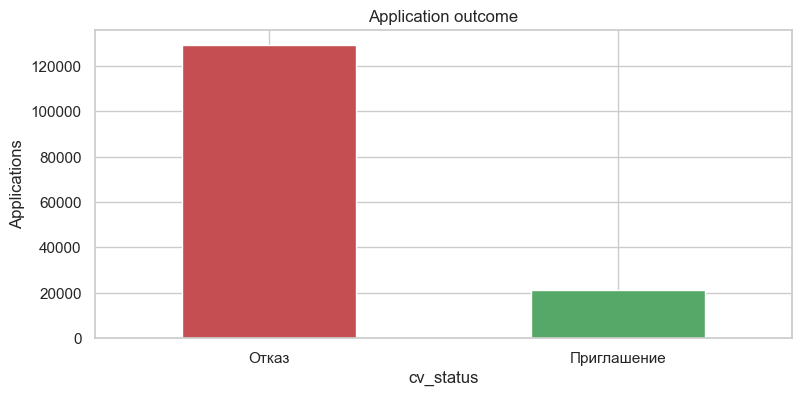

In [5]:
counts = df[LABEL].value_counts(dropna=False)
print(counts)
print()
print((counts / len(df) * 100).round(1).astype(str) + " %")

df["is_positive"] = (df[LABEL] == POSITIVE).astype(int)
print("\nPositive rate:", f"{df['is_positive'].mean():.1%}")

counts.plot(kind="bar", color=["#C44E52", "#55A868"])
plt.title("Application outcome")
plt.ylabel("Applications")
plt.xticks(rotation=0)
plt.savefig("figures/D4_label_balance.png", dpi=150, bbox_inches="tight")
plt.show()

The classes are imbalanced at roughly 1 invitation for every 6 rejections. That is normal for
recruitment data and is not a problem for ranking metrics such as Recall@K, which only need to
know which items are relevant.

## 4. Can we rank multiple jobs per applicant?

This decides the whole evaluation design, so it is the most important cell in the notebook.

In [6]:
apps = df.groupby(ID_CV).size()
pos_per_cv = df.groupby(ID_CV)["is_positive"].sum()

print("Applications per resume")
print(apps.describe().round(2))
print()
for k in [1, 2, 3, 5, 10]:
    print(f"  resumes with >= {k:2d} applications: {(apps >= k).mean():6.1%}  ({(apps >= k).sum():,})")
print()
print(f"Resumes with at least one invitation: {(pos_per_cv > 0).sum():,} ({(pos_per_cv > 0).mean():.1%})")
print(f"Resumes with no invitation at all   : {(pos_per_cv == 0).sum():,}")

Applications per resume
count    65714.00
mean         2.29
std         15.51
min          1.00
25%          1.00
50%          1.00
75%          2.00
max       3808.00
dtype: float64

  resumes with >=  1 applications: 100.0%  (65,714)
  resumes with >=  2 applications:  36.5%  (23,972)
  resumes with >=  3 applications:  20.6%  (13,556)
  resumes with >=  5 applications:   8.6%  (5,648)
  resumes with >= 10 applications:   2.5%  (1,644)

Resumes with at least one invitation: 14,033 (21.4%)
Resumes with no invitation at all   : 51,681


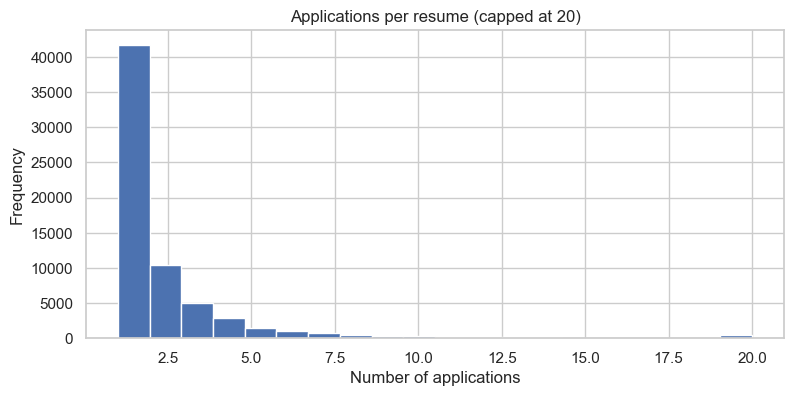

In [7]:
apps.clip(upper=20).plot(kind="hist", bins=20)
plt.title("Applications per resume (capped at 20)")
plt.xlabel("Number of applications")
plt.savefig("figures/D4_apps_per_applicant.png", dpi=150, bbox_inches="tight")
plt.show()

### How to read the result

The mean is about 2.3 applications per resume, so **re-ranking only the vacancies a person applied to
gives a list of 2 or 3 items**, which is far too short for Recall@10.

We therefore use a **retrieval** setup instead, which is also what a real recommender does:

- For each resume that received at least one invitation, the **relevant items** are the vacancies
  where the outcome was an invitation.
- The **candidate pool** is a larger set of vacancies, not just the ones applied to.
- We then rank the pool and measure Recall@K and NDCG@K.

Two sensible pool definitions, both worth reporting:

| Pool | Size | Random Recall@10 | Comment |
|---|---|---|---|
| All vacancies | about 43,800 | 0.0002 | Hardest and most realistic |
| Same region as the candidate | a few thousand | higher | Realistic, since 95% of candidates will not relocate |
| 1 positive + 999 sampled negatives | 1,000 | 0.01 | Cheap for fast model comparison |

Compare this with the D1 probe from the proposal, where only 20 job titles existed and random
guessing already scored Recall@10 = 0.50. Here a random baseline scores close to zero, so any
improvement the models make is real.

In [8]:
# Build the evaluation set: resumes with at least one invitation
eval_cv = pos_per_cv[pos_per_cv > 0].index
print(f"Evaluation resumes: {len(eval_cv):,}")
print(f"Their invitations : {df[df[ID_CV].isin(eval_cv)]['is_positive'].sum():,}")

inv_per_cv = pos_per_cv[pos_per_cv > 0]
print("\nInvitations per evaluation resume:")
print(inv_per_cv.describe().round(2))

Evaluation resumes: 14,033
Their invitations : 20,990

Invitations per evaluation resume:
count    14033.00
mean         1.50
std          2.35
min          1.00
25%          1.00
50%          1.00
75%          2.00
max        217.00
Name: is_positive, dtype: float64


## 5. The skills problem

The instructor's research question is about skill-aware matching, so we check whether the
dataset actually contains skills.

Share of rows where the skill field is empty:
hardSkills_cv         68.3 %
softSkills_cv         87.4 %
hardSkills_vacancy    90.1 %
skills_cv             93.1 %
skills_vacancy        93.1 %
softSkills_vacancy    97.0 %
dtype: object


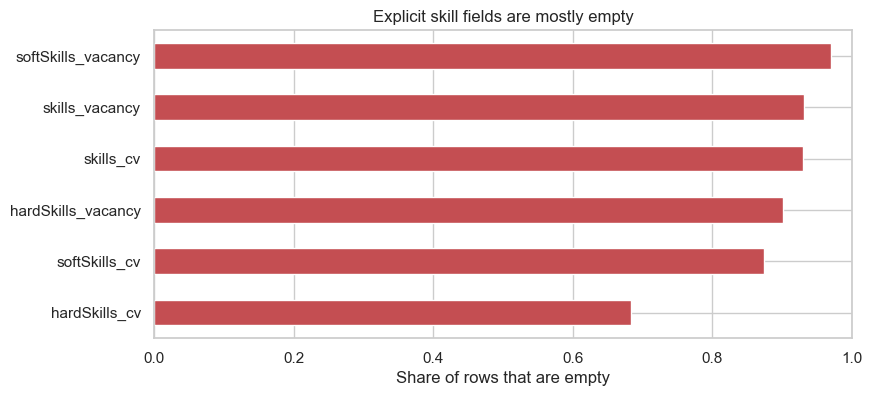

In [9]:
skill_cols = [c for c in [CV_SKILLS, CV_HARD, CV_SOFT, VC_SKILLS, VC_HARD, VC_SOFT] if c in df.columns]

def share_empty(s):
    """Share of rows where the field is missing or an empty list."""
    text = s.fillna("[]").astype(str).str.strip()
    return (text.isin(["[]", "", "nan", "null"])).mean()

empty = pd.Series({c: share_empty(df[c]) for c in skill_cols}).sort_values()
print("Share of rows where the skill field is empty:")
print((empty * 100).round(1).astype(str) + " %")

empty.plot(kind="barh", color="#C44E52")
plt.xlim(0, 1)
plt.title("Explicit skill fields are mostly empty")
plt.xlabel("Share of rows that are empty")
plt.savefig("figures/D4_skill_emptiness.png", dpi=150, bbox_inches="tight")
plt.show()

### What this means for the project

The explicit skill lists cover only a small part of the data, so a model that reads `skills_cv`
and `skills_vacancy` directly would have nothing to work with for most pairs.

**Skills must be extracted from free text.** The usable text fields are listed in the next cell.
This does not weaken the project. It makes the research question sharper, because extracting
skills from text and mapping them to a taxonomy is exactly the step the instructor asked us to test.

Note how many pairs have skills on **both** sides, since only those can be used for a pure
skill-overlap comparison.

In [10]:
cv_has = df[CV_SKILLS].fillna("[]").astype(str).str.strip().ne("[]")
vc_has = df[VC_SKILLS].fillna("[]").astype(str).str.strip().ne("[]")
print(f"Rows with skills on the candidate side: {cv_has.mean():.1%}")
print(f"Rows with skills on the vacancy side  : {vc_has.mean():.1%}")
print(f"Rows with skills on BOTH sides        : {(cv_has & vc_has).mean():.1%}  ({(cv_has & vc_has).sum():,} rows)")

Rows with skills on the candidate side: 6.9%
Rows with skills on the vacancy side  : 6.9%
Rows with skills on BOTH sides        : 0.8%  (1,205 rows)


## 5.1 Text fields available for skill extraction

In [11]:
text_fields = {
    "candidate: desired position": CV_POSITION,
    "candidate: work experience (JSON)": CV_WORK,
    "candidate: education (JSON)": CV_EDU,
    "vacancy: title": VC_NAME,
    "vacancy: position requirements": VC_REQ,
    "vacancy: responsibilities": VC_RESP,
    "vacancy: qualifications": VC_QUAL,
}

rows = []
for name, col in text_fields.items():
    if col in df.columns:
        text = df[col].dropna().astype(str)
        rows.append({
            "field": name,
            "column": col,
            "filled %": f"{df[col].notna().mean():.0%}",
            "mean length": int(text.str.len().mean()),
            "unique": f"{df[col].nunique():,}",
        })
pd.DataFrame(rows)

,field,column,filled %,mean length,unique
0,candidate: desired position,positionName,100%,18,"18,113"
1,candidate: work experience (JSON),workExperienceList,100%,1097,"58,346"
2,candidate: education (JSON),educationList,100%,207,"59,118"
3,vacancy: title,vacancyName,100%,24,"14,595"
4,vacancy: position requirements,positionRequirements,99%,193,"35,457"
5,vacancy: responsibilities,responsibilities,100%,382,"40,109"
6,vacancy: qualifications,qualifications,99%,193,"35,457"


In [12]:
# Look at one example of the richest vacancy text
example = df[VC_REQ].dropna().iloc[0]
print("positionRequirements example:\n")
print(example[:500])

positionRequirements example:

Наличие опыта работы (желательно).


`positionRequirements`, `responsibilities` and `qualifications` are the fields a skill extractor
should read on the vacancy side. On the candidate side, `workExperienceList` holds a JSON list
where each job has a `demands` field describing the work done.

In [13]:
# workExperienceList is JSON text. This pulls out the free-text part.
def experience_text(cell):
    try:
        items = json.loads(cell) if isinstance(cell, str) else []
    except (json.JSONDecodeError, TypeError):
        return ""
    parts = []
    for it in items:
        if isinstance(it, dict):
            parts.append(str(it.get("jobTitle", "")))
            parts.append(str(it.get("demands", "")))
    return " ".join(p for p in parts if p and p != "None")

sample_exp = df[CV_WORK].dropna().head(200).apply(experience_text)
print("Non-empty after parsing:", (sample_exp.str.len() > 0).mean())
print("\nExample:\n", sample_exp[sample_exp.str.len() > 0].iloc[0][:400])

Non-empty after parsing: 0.87

Example:
 Музыкальный руководитель Формирует их эстетический вкус, используя разные виды и формы организации музыкальной деятельности. Почтальон 2 класса Доставка корреспонденции. Специалист по телемаркетингу Обзвон потенциальных покупателей и продажа услуг.


## 6. Job categories

Professional spheres: 35

professionalSphereName
Производство                                           17388
Здравоохранение и социальное обеспечение               14894
Образование, наука                                     12556
Продажи, закупки, снабжение, торговля                  11182
ЖКХ, эксплуатация                                       8172
Бухгалтерия, налоги, управленческий учет                7585
Транспорт, автобизнес, логистика, склад, ВЭД            6726
Государственная служба, некоммерческие организации      6424
Административная работа, секретариат, АХО               6421
Пищевая промышленность                                  5625
Информационные технологии, телекоммуникации, связь      4990
Работы, не требующие квалификации                       4787
Строительство, ремонт, стройматериалы, недвижимость     4495
Машиностроение                                          3964
Рабочие специальности                                   3762
Name: count, dtype: int64


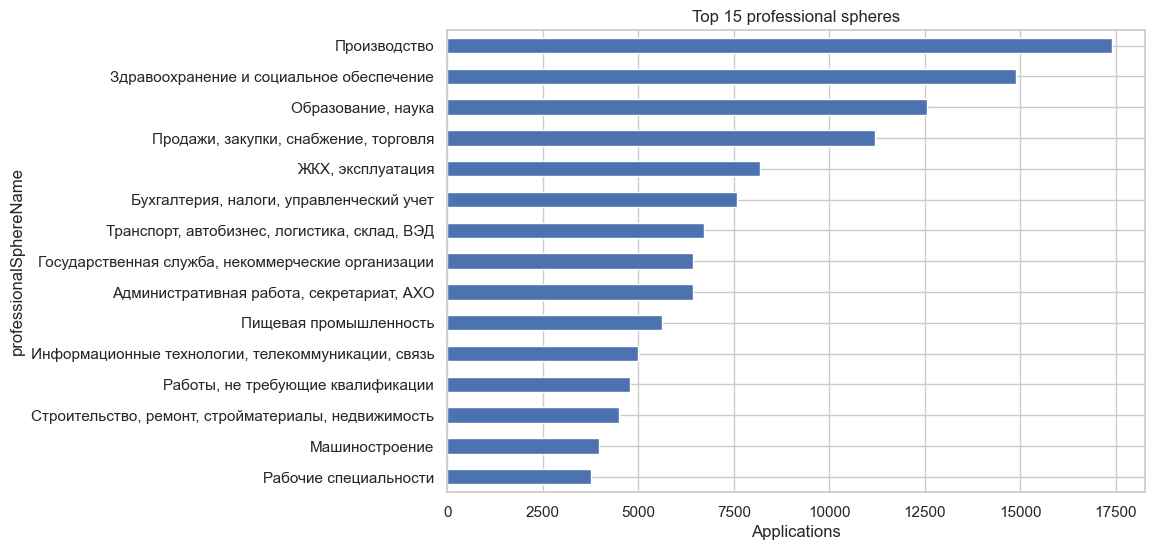

In [14]:
spheres = df[VC_SPHERE].value_counts()
print("Professional spheres:", df[VC_SPHERE].nunique())
print()
print(spheres.head(15))

spheres.head(15).sort_values().plot(kind="barh", figsize=(9, 6))
plt.title("Top 15 professional spheres")
plt.xlabel("Applications")
plt.savefig("figures/D4_spheres.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
# How much of the dataset is IT, data or engineering?
it_pattern = "информацион|it|программ|разработ|данн|аналитик|компьютер|связь|телеком"
is_it = df[VC_SPHERE].astype(str).str.lower().str.contains(it_pattern, regex=True, na=False)
print(f"Applications in IT-like spheres: {is_it.sum():,} ({is_it.mean():.1%})")
print()
print("Spheres that matched:")
print(df.loc[is_it, VC_SPHERE].value_counts())
print()
print("Unique resumes in that subset :", df.loc[is_it, ID_CV].nunique())
print("Unique vacancies in that subset:", df.loc[is_it, ID_VACANCY].nunique())

Applications in IT-like spheres: 4,990 (3.3%)

Spheres that matched:
professionalSphereName
Информационные технологии, телекоммуникации, связь    4990
Name: count, dtype: int64

Unique resumes in that subset : 2841
Unique vacancies in that subset: 1346


### Scope decision

The dataset covers the whole Russian labour market, not AI and data roles. Two options:

1. **Use the full dataset** and describe the project as general resume-to-vacancy matching.
   More data, stronger results, but it drops the AI and data framing from the proposal.
2. **Filter to the IT-like spheres** and keep the original framing. Check the counts printed
   above first. If the subset leaves only a few thousand applications and few resumes with
   invitations, the evaluation becomes too small to be reliable.

Report whichever you choose and the numbers behind the choice. The instructor asked for the
dataset to be validated, and this is exactly the kind of finding that validation is meant to surface.

## 7. Missing values and duplicates

datePublished             2.8
qualifications            1.3
positionRequirements      1.3
regionName                1.3
experienceRequirements    0.3
responsibilities          0.2
localityName              0.1
positionName              0.0
professionalSphereName    0.0
idCv                      0.0
skills_vacancy            0.0
softSkills_vacancy        0.0
hardSkills_vacancy        0.0
vacancyName               0.0
idVacancy                 0.0
workExperienceList        0.0
softSkills_cv             0.0
hardSkills_cv             0.0
educationList             0.0
experience                0.0
skills_cv                 0.0
dateCreate                0.0
cv_status                 0.0
is_positive               0.0


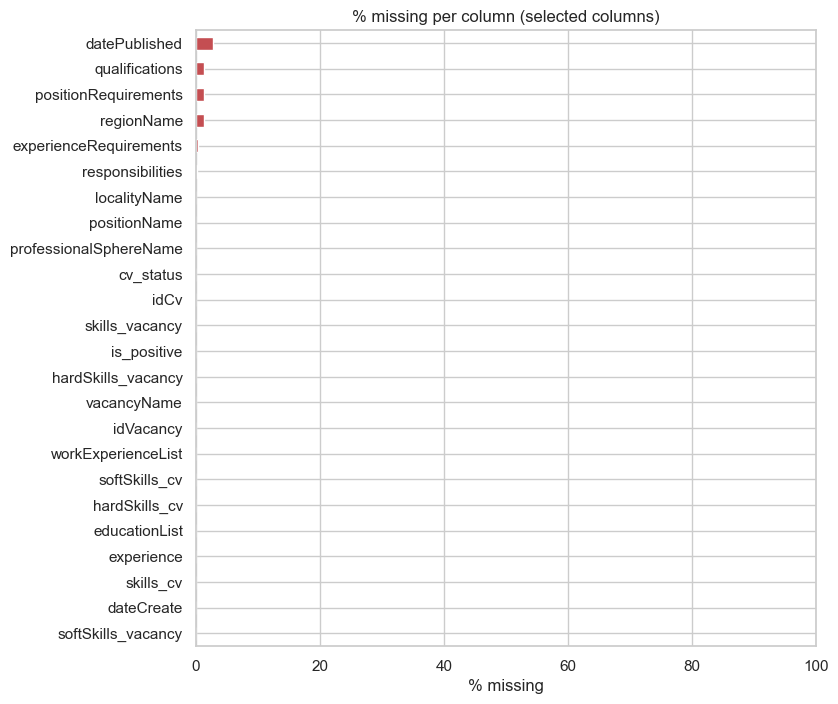

In [16]:
missing = (df.isnull().mean() * 100).sort_values(ascending=False)
print(missing.round(1).to_string())

missing.sort_values().plot(kind="barh", figsize=(8, 8), color="#C44E52")
plt.xlim(0, 100)
plt.title("% missing per column (selected columns)")
plt.xlabel("% missing")
plt.savefig("figures/D4_missing_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
print("Exact duplicate rows:", df.duplicated().sum())

pair_dupes = df.duplicated(subset=[ID_CV, ID_VACANCY]).sum()
print("Duplicate (resume, vacancy) pairs:", f"{pair_dupes:,}")

if pair_dupes:
    # Do repeated pairs ever disagree on the outcome?
    conflict = (df.groupby([ID_CV, ID_VACANCY])["is_positive"].nunique() > 1).sum()
    print("Pairs with conflicting outcomes:", conflict)
    print("Drop or merge these before building the evaluation set.")

Exact duplicate rows: 53555
Duplicate (resume, vacancy) pairs: 56,738
Pairs with conflicting outcomes: 3183
Drop or merge these before building the evaluation set.


Columns the data card shows as useless, worth dropping if you load the full file:
`academicDegree` and `oknpoCode` are 100% null, `deleted` is always false, and `isModerated`
is always true. Also note that `salary_cv`, `salaryMin_cv` and `salaryMax_cv` have identical
distributions, so they appear to be copies of one field.

## 8. Columns to exclude from the model

The dataset records the candidate's age, gender, birth date and region. Training on past recruiter
decisions would copy any bias in those decisions into the recommendations, so these columns stay out
of the model features. We keep them only to describe the dataset.

In [18]:
SENSITIVE = ["gender", "age", "birthday"]
print("Excluded from model features:", SENSITIVE)
print()
print("Note: the data card reports a minimum age of 14, so the dataset contains minors.")
print("Region is kept only as a hard filter for the candidate pool, not as a learned feature,")
print("because 95% of candidates state they will not relocate.")

Excluded from model features: ['gender', 'age', 'birthday']

Note: the data card reports a minimum age of 14, so the dataset contains minors.
Region is kept only as a hard filter for the candidate pool, not as a learned feature,
because 95% of candidates state they will not relocate.


## 9. Train and test split

There is no explicit application date. The closest usable dates are the vacancy publication date
and the resume creation date. Two options:

1. **Chronological on the vacancy date.** Train on vacancies published earlier, test on later ones.
   Check the range first, because the card shows most vacancies were published between February
   and April 2025, which is a narrow window.
2. **Split by resume.** All applications of one resume go to the same side. Never split one resume
   across train and test, or the model sees part of the answer.

In [19]:
if VC_DATE in df.columns:
    dates = pd.to_datetime(df[VC_DATE], errors="coerce", format="mixed")
    print("Vacancy publication dates:", dates.min(), "to", dates.max())
    print("Unparsed:", dates.isna().sum())
    cutoff = dates.quantile(0.8)
    print("80% cutoff:", cutoff)
    print("Train:", (dates <= cutoff).sum(), " Test:", (dates > cutoff).sum())

Vacancy publication dates: 2022-07-18 15:13:30+03:00 to 2025-04-09 13:38:20+03:00
Unparsed: 4147
80% cutoff: 2025-03-21 16:12:14+03:00
Train: 117099  Test: 29247


In [20]:
# Split by resume, so that one person never appears on both sides
rng = np.random.default_rng(42)
ids = df[ID_CV].unique()
rng.shuffle(ids)
cut = int(len(ids) * 0.8)
train_ids, test_ids = set(ids[:cut]), set(ids[cut:])

train = df[df[ID_CV].isin(train_ids)]
test = df[df[ID_CV].isin(test_ids)]
print(f"Train: {len(train):,} applications from {len(train_ids):,} resumes")
print(f"Test : {len(test):,} applications from {len(test_ids):,} resumes")
print(f"Test resumes with an invitation: {test.groupby(ID_CV)['is_positive'].max().sum():,}")

Train: 121,179 applications from 52,571 resumes
Test : 29,314 applications from 13,143 resumes
Test resumes with an invitation: 2,842


## 10. Limitations of using recruitment outcomes as relevance labels

Write these into the report. The instructor asked for them specifically.

1. **An invitation is not the same as a good match.** A recruiter may invite a weak candidate
   because few people applied, or reject a strong one because the role was already filled.
   The label records the recruiter's decision, not true suitability.

2. **Rejection is not proof of a bad match.** Common reasons unrelated to fit: the vacancy closed,
   salary expectations differed, the candidate withdrew, or nobody opened the application. With 86%
   rejections, a large share of the negatives are noisy.

3. **Missing not at random.** We only see outcomes for vacancies a person actually applied to.
   A well-suited vacancy the person never saw has no label, so during evaluation it counts as not
   relevant even though it is. This systematically pushes Recall@K down and is the main reason the
   absolute scores here will look low compared with published benchmarks.

4. **Popularity bias.** Popular vacancies collect more applications and therefore more invitations,
   so a model can score well simply by recommending popular jobs. A popularity baseline must be
   reported alongside the models to show that real matching is happening.

5. **Demographic bias.** The data contains age, gender and region. Past recruiter decisions may
   reflect bias on these attributes, and a model trained on those decisions would reproduce it.
   We exclude them from the features and state this in the methodology.

6. **One country, one platform, one period.** The data comes from a single Russian public employment
   portal, and most vacancies were published within a few months of early 2025. Results may not
   transfer to other markets, languages or periods.

7. **Sparse skill fields.** Because the explicit skill lists are empty in over 90% of rows, any
   skill signal is produced by our own extraction step. Errors in extraction are therefore part of
   the measured result, and the comparison against the text-only baseline is what isolates their effect.

## 11. Summary table for the report

In [21]:
summary = pd.DataFrame([
    ["Applications (rows)", f"{len(df):,}"],
    ["Unique resumes", f"{df[ID_CV].nunique():,}"],
    ["Unique vacancies", f"{df[ID_VACANCY].nunique():,}"],
    ["Mean applications per resume", f"{apps.mean():.2f}"],
    ["Median applications per resume", f"{apps.median():.0f}"],
    ["Invitation rate", f"{df['is_positive'].mean():.1%}"],
    ["Resumes with >= 1 invitation", f"{(pos_per_cv > 0).sum():,} ({(pos_per_cv > 0).mean():.1%})"],
    ["Professional spheres", f"{df[VC_SPHERE].nunique()}"],
    ["Rows with candidate skills filled", f"{cv_has.mean():.1%}"],
    ["Rows with vacancy skills filled", f"{vc_has.mean():.1%}"],
    ["Exact duplicate rows", f"{df.duplicated().sum():,}"],
    ["Duplicate (resume, vacancy) pairs", f"{pair_dupes:,}"],
], columns=["Check", "Value"])

summary.to_csv("figures/D4_summary.csv", index=False)
summary

,Check,Value
0,Applications (rows),"150,493"
1,Unique resumes,"65,714"
2,Unique vacancies,"43,756"
3,Mean applications per resume,2.29
4,Median applications per resume,1
5,Invitation rate,13.9%
6,Resumes with >= 1 invitation,"14,033 (21.4%)"
7,Professional spheres,35
8,Rows with candidate skills filled,6.9%
9,Rows with vacancy skills filled,6.9%


### Decision after running this notebook

- **Evaluation setup:** retrieval, not re-ranking. For each resume with an invitation, rank a pool of
  vacancies and measure Recall@K and NDCG@K. Report the pool size next to every score, because the
  random baseline depends on it.
- **Skills:** extract from free text, then map to a taxonomy. The explicit skill fields are too sparse
  to use on their own, and this is the finding that justifies the whole research question.
- **Scope:** decide between the full labour market and the IT subset using the counts from Section 6.

In [22]:
# 12.1 Remove duplicates. When a pair has conflicting outcomes, keep the invitation.
before = len(df)
clean = (df.sort_values("is_positive", ascending=False)
           .drop_duplicates(subset=[ID_CV, ID_VACANCY], keep="first")
           .reset_index(drop=True))

print(f"Rows before: {before:,}")
print(f"Rows after : {len(clean):,}   removed {before-len(clean):,} ({1-len(clean)/before:.1%})")
print(f"Invitation rate  before {df['is_positive'].mean():.1%}   after {clean['is_positive'].mean():.1%}")
print(f"Resumes {clean[ID_CV].nunique():,}   Vacancies {clean[ID_VACANCY].nunique():,}")

Rows before: 150,493
Rows after : 93,755   removed 56,738 (37.7%)
Invitation rate  before 13.9%   after 15.9%
Resumes 65,714   Vacancies 43,756


In [23]:
# 12.2 The most active resumes. One of them submitted 3,808 applications.
apps_clean = clean.groupby(ID_CV).size()
print(apps_clean.describe().round(2))
print("\nTop 10 most active resumes:")
print(apps_clean.sort_values(ascending=False).head(10).to_string())

CAP = 50
heavy = apps_clean[apps_clean > CAP].index
rows_heavy = clean[ID_CV].isin(heavy)
print(f"\nResumes with more than {CAP} applications: {len(heavy):,}")
print(f"They cover {rows_heavy.sum():,} rows ({rows_heavy.mean():.1%} of the data)")

count    65714.00
mean         1.43
std          1.33
min          1.00
25%          1.00
50%          1.00
75%          1.00
max         95.00
dtype: float64

Top 10 most active resumes:
idCv
e0db3e20-a0ee-11ef-b469-c7bd3a8c3ec7    95
421727c0-7f26-11ea-ba3b-e736a3d3ed84    74
557edd20-8695-11ed-bde9-e57b87a63fa7    41
faa859d0-4a79-11ef-918e-716c765c9fe3    38
6f45de70-dca1-11ef-aad2-e7f46f7514cd    35
68158c70-1801-11ed-b195-4d0c8161e2ef    33
a7df0050-092e-11ef-b7e0-716c765c9fe3    29
3f427360-b6da-11ef-886f-e7f46f7514cd    29
4e001930-c781-11eb-bac0-6db06c9eaf56    28
1541ebb0-e2e3-11ef-a168-716c765c9fe3    28

Resumes with more than 50 applications: 2
They cover 169 rows (0.2% of the data)


In [24]:
# 12.3 Final evaluation set
pos_clean = clean.groupby(ID_CV)["is_positive"].sum()
eval_cv = pos_clean[pos_clean > 0]
print(f"Resumes with >= 1 invitation: {len(eval_cv):,} ({(pos_clean > 0).mean():.1%})")
print(f"Invitations per such resume: median {eval_cv.median():.0f}, mean {eval_cv.mean():.2f}, max {eval_cv.max():.0f}")
print(f"\nRandom Recall@10 if the pool is all vacancies: {10/clean[ID_VACANCY].nunique():.5f}")

Resumes with >= 1 invitation: 14,033 (21.4%)
Invitations per such resume: median 1, mean 1.06, max 17

Random Recall@10 if the pool is all vacancies: 0.00023


In [25]:
# 12.4 Is the IT subset big enough to stand on its own?
it = clean[clean[VC_SPHERE].astype(str).str.contains("Информационные технологии", na=False)]
it_pos = it.groupby(ID_CV)["is_positive"].sum()
print(f"IT applications                : {len(it):,}")
print(f"IT resumes                     : {it[ID_CV].nunique():,}")
print(f"IT vacancies                   : {it[ID_VACANCY].nunique():,}")
print(f"IT resumes with >= 1 invitation: {(it_pos > 0).sum():,}")

IT applications                : 3,288
IT resumes                     : 2,841
IT vacancies                   : 1,346
IT resumes with >= 1 invitation: 251
